<a href="https://colab.research.google.com/github/lilianabs/nlp-basic-examples/blob/main/Fine_tuning_encoder_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
#!pip install "datasets>=2.18.0,<3" "transformers>=4.38.2" "sentence-transformers>=2.5.1" "setfit>=1.0.3" "accelerate>=0.27.2" "seqeval>=1.2.2"

In [7]:
from datasets import load_dataset

# Prepare data and splits
tomatoes = load_dataset("cornell-movie-review-data/rotten_tomatoes")
train_data, test_data = tomatoes["train"], tomatoes["test"]

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

## Load BERT model

In [9]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Load Model and Tokenizer
model_id = "bert-base-cased"
model = AutoModelForSequenceClassification.from_pretrained(model_id, num_labels=2)
tokenizer = AutoTokenizer.from_pretrained(model_id)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

In [10]:
from transformers import DataCollatorWithPadding

# Pad to the longest sequence in the batch
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def preprocess_function(examples):
   """Tokenize input data"""
   return tokenizer(examples["text"], truncation=True)

# Tokenize train/test data
tokenized_train = train_data.map(preprocess_function, batched=True)
tokenized_test = test_data.map(preprocess_function, batched=True)

Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

In [11]:
import numpy as np
import evaluate


def compute_metrics(eval_pred):
    """Calculate F1 score"""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    load_f1 = evaluate.load("f1")
    f1 = load_f1.compute(predictions=predictions, references=labels)["f1"]
    return {"f1": f1}

In [13]:
from transformers import TrainingArguments, Trainer

# Training arguments for parameter tuning
training_args = TrainingArguments(
   "model",
   learning_rate=2e-5,
   per_device_train_batch_size=16,
   per_device_eval_batch_size=16,
   num_train_epochs=1,
   weight_decay=0.01,
   save_strategy="epoch",
   report_to="none"
)

# Trainer which executes the training process
trainer = Trainer(
   model=model,
   args=training_args,
   train_dataset=tokenized_train,
   eval_dataset=tokenized_test,
   processing_class=tokenizer,
   data_collator=data_collator,
   compute_metrics=compute_metrics,
)

In [14]:
trainer.train()

Step,Training Loss
500,0.441638


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=534, training_loss=0.43565907281882754, metrics={'train_runtime': 114.4566, 'train_samples_per_second': 74.526, 'train_steps_per_second': 4.666, 'total_flos': 227605451772240.0, 'train_loss': 0.43565907281882754, 'epoch': 1.0})

In [16]:
trainer.evaluate()

Training Loss,Validation Loss,Epoch,F1
0.106547,0.680362,3,0.846968


{'eval_loss': 0.6803615689277649, 'eval_f1': 0.8469682386910491}

### Configuración avanzada para registrar la pérdida
Para visualizar de forma óptima la pérdida, actualizaremos los argumentos de entrenamiento para evaluar en cada época (`eval_strategy="epoch"`) y registrar las métricas internas cada 50 pasos (`logging_steps=50`).

In [17]:
# Modificamos los argumentos de entrenamiento para habilitar el registro de la pérdida
training_args = TrainingArguments(
   "model",
   learning_rate=2e-5,
   per_device_train_batch_size=16,
   per_device_eval_batch_size=16,
   num_train_epochs=3, # Aumentamos las épocas para ver mejor la curva
   weight_decay=0.01,
   eval_strategy="epoch", # Evaluar al final de cada época
   save_strategy="epoch",
   logging_steps=50,      # Registrar pérdida cada 50 pasos
   report_to="none"
)

trainer = Trainer(
   model=model,
   args=training_args,
   train_dataset=tokenized_train,
   eval_dataset=tokenized_test,
   processing_class=tokenizer,
   data_collator=data_collator,
   compute_metrics=compute_metrics,
)

# Ejecutamos el entrenamiento con el registro activo
trainer.train()

Epoch,Training Loss,Validation Loss,F1
1,0.086707,0.790971,0.837668
2,0.046003,0.934547,0.847847
3,0.051628,0.988939,0.851429


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1602, training_loss=0.048003174003911846, metrics={'train_runtime': 355.7595, 'train_samples_per_second': 71.931, 'train_steps_per_second': 4.503, 'total_flos': 681337383407880.0, 'train_loss': 0.048003174003911846, 'epoch': 3.0})

### Graficar las curvas de pérdida (Training & Validation Loss)
Una vez terminado el entrenamiento, podemos acceder a `trainer.state.log_history` para extraer y graficar la pérdida de entrenamiento y validación utilizando `matplotlib`.

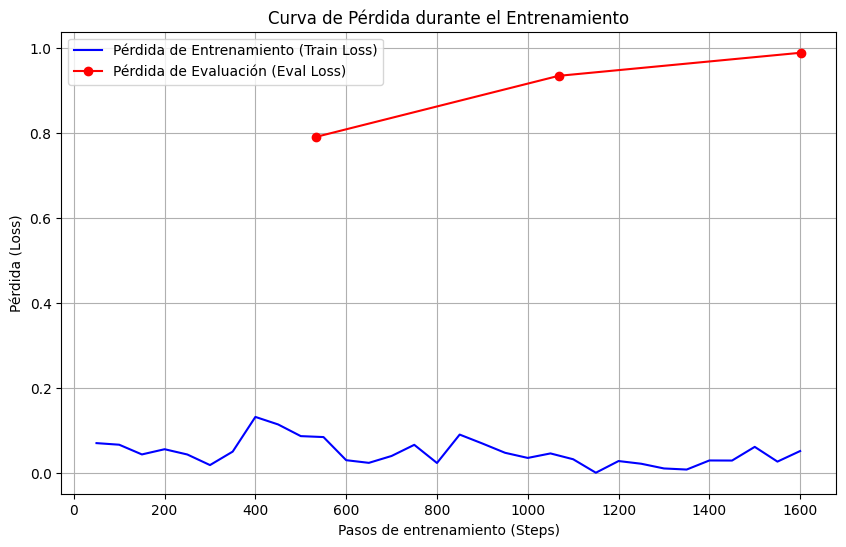

In [18]:
import matplotlib.pyplot as plt

# Extraer el historial de logs del trainer
history = trainer.state.log_history

train_loss = [x['loss'] for x in history if 'loss' in x]
train_steps = [x['step'] for x in history if 'loss' in x]

eval_loss = [x['eval_loss'] for x in history if 'eval_loss' in x]
eval_steps = [x['step'] for x in history if 'eval_loss' in x]

# Graficar los resultados
plt.figure(figsize=(10, 6))
plt.plot(train_steps, train_loss, label='Pérdida de Entrenamiento (Train Loss)', color='blue')
if eval_loss:
    plt.plot(eval_steps, eval_loss, label='Pérdida de Evaluación (Eval Loss)', color='red', marker='o')

plt.title('Curva de Pérdida durante el Entrenamiento')
plt.xlabel('Pasos de entrenamiento (Steps)')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()